In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

In [3]:
# -------------------------------------------------------------
# STEP 1: Load Data & Preprocessing
# -------------------------------------------------------------
# Load dataset
df = pd.read_csv('heart.csv')

# Drop duplicate rows present in the 1025-row Kaggle version to prevent data leakage
df = df.drop_duplicates()

# Separate features (X) and target variable (y)
X = df.drop(columns=['target'])
y = df['target']

# Split data: 80% Training, 20% Testing with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numerical features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# -------------------------------------------------------------
# STEP 2: Model Building & Training
# -------------------------------------------------------------
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [6]:
# -------------------------------------------------------------
# STEP 3: Model Evaluation Metrics
# -------------------------------------------------------------
print("================ MODEL EVALUATION METRICS ================")
print(f"Accuracy Score  : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision Score : {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Recall Score    : {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"F1-Score        : {f1_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

================ MODEL EVALUATION METRICS ================
Accuracy Score  : 80.33%
Precision Score : 80.00%
Recall Score    : 84.85%
F1-Score        : 82.35%

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [7]:
# -------------------------------------------------------------
# STEP 4: Feature Importance / Odds Ratios
# -------------------------------------------------------------
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
    'Odds Ratio': np.exp(model.coef_[0])
}).sort_values(by='Coefficient', ascending=False)

print("================ FEATURE IMPORTANCE / WEIGHTS ================")
print(coefficients.to_string(index=False))

================ FEATURE IMPORTANCE / WEIGHTS ================
 Feature  Coefficient  Odds Ratio
      cp     0.978893    2.661507
 thalach     0.818189    2.266392
   slope     0.309090    1.362185
 restecg     0.224004    1.251076
     age     0.087868    1.091844
     fbs    -0.112431    0.893659
    chol    -0.279967    0.755809
trestbps    -0.358746    0.698552
 oldpeak    -0.400050    0.670287
   exang    -0.499109    0.607072
    thal    -0.521572    0.593587
      ca    -0.740095    0.477069
     sex    -0.876002    0.416445


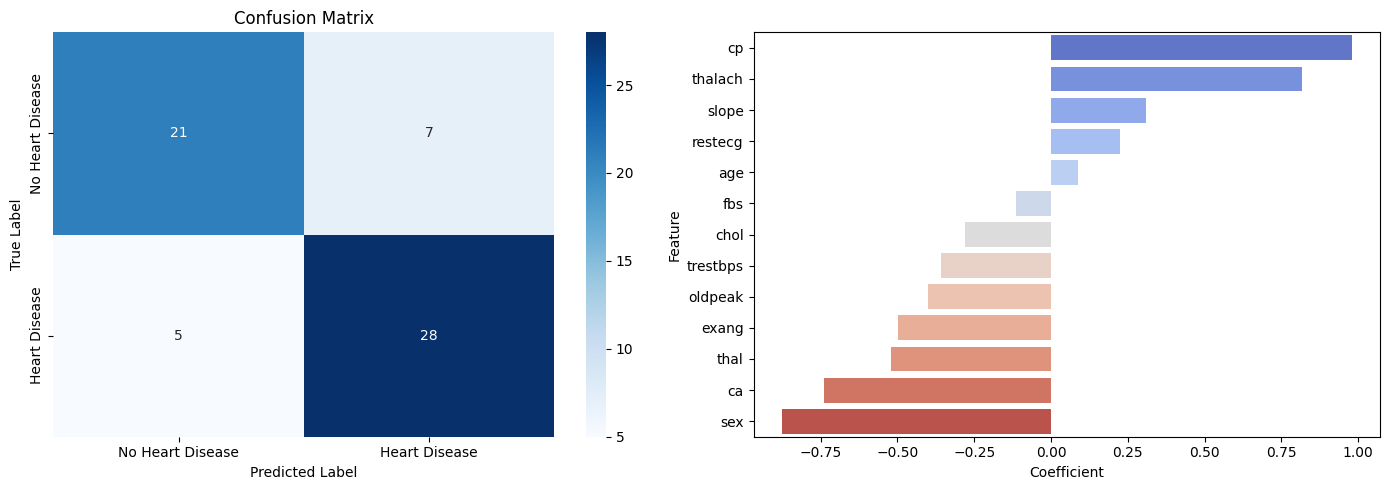

In [10]:
# -------------------------------------------------------------
# STEP 5: Visualizations
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['No Heart Disease', 'Heart Disease'],
    yticklabels=['No Heart Disease', 'Heart Disease']
)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot 2: Feature Importance Bar Plot
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=coefficients,
    hue='Feature',
    palette='coolwarm',
    legend=False,
    ax=axes[1]
)

plt.tight_layout()
plt.show()


In [11]:
# -------------------------------------------------------------
# STEP 6: Single Patient Sample Prediction Pipeline
# -------------------------------------------------------------
# Example sample input patient data
sample_patient = pd.DataFrame([[52, 1, 0, 125, 212, 0, 1, 168, 0, 1.0, 2, 2, 3]], columns=X.columns)
sample_patient_scaled = scaler.transform(sample_patient)

prediction = model.predict(sample_patient_scaled)[0]
probability = model.predict_proba(sample_patient_scaled)[0][1]

print("\n================ SAMPLE PATIENT PREDICTION ================")
print(f"Prediction Output  : {'Heart Disease' if prediction == 1 else 'No Heart Disease'}")
print(f"Probability Score  : {probability * 100:.2f}%")


================ SAMPLE PATIENT PREDICTION ================
Prediction Output  : No Heart Disease
Probability Score  : 24.89%
